# 20 — Confounder Analysis: Does the Fusion Model Rely on Demographic Signal?

**Why this notebook exists.** Phase 3's EDA found that Age (p<0.0001), Height (p<0.0001, likely
gender-driven), BMI (p<0.0001), and Gender (chi-square p<0.0001) all differ significantly between
the Control and DM groups. That means demographics alone carry real information about group
membership in this dataset — which raises the question of whether the project's headline result,
the GAT+TCI fusion model (`fusion_b_prob`, the winning unweighted-average fusion from Phase 16),
is actually detecting thermal pathology, or is partly/mostly picking up on demographic shortcuts
correlated with diagnosis.

This notebook runs three independent checks:

1. **Within-class probability–demographic correlation** — if the model's predicted probability
   still tracks Age/BMI *within* a single true class (i.e., among people who are all Control, or
   all DM), that's a red flag for demographic shortcutting rather than pathology detection.
2. **Demographics-only baseline classifier** — direct context for how much signal Age/Gender/BMI
   alone provide, compared against the known TCI-only AUC (0.859) and fusion AUC (0.889).
3. **Demographically-atypical-subject stress test** (the most convincing check) — does the model
   still classify correctly the subjects whose age/BMI profile looks like the *wrong* group (a
   young diabetic subject, or an old control subject)?

**Known data quality issue — handled explicitly, not imputed.** 27 of 167 subjects (all DM) have
null `Weight_kg` / `Height_m` / `BMI` in `subject_metadata.csv` (documented in Phase 5). Any
BMI-based analysis here uses **complete-case subjects only** (n=140), stated explicitly at each
step. We deliberately do **not** impute these values — per-Group imputation would leak the Group
label directly into an engineered feature, corrupting exactly the confound check this notebook
exists to perform. Age and Gender have zero missingness and use the full n=167 throughout.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Reference values from earlier phases (not recomputed here — see Section 4/9)
TCI_ONLY_AUC = 0.859   # Phase 14
FUSION_AUC = 0.889     # Phase 16


## 1. Setup — Load, Merge, and Validate the Two Source Files

We load `subject_metadata.csv` (167 rows, demographics + Group label) and
`fusion_pooled_predictions.csv` (167 rows, model probabilities including `fusion_b_prob`, the
project's headline result), merge them on subject ID, and assert the merge is clean (167/167
matched, and the group/label information agrees between the two files).

We also print the BMI missingness count (expected: 27, all DM) as an explicit reminder of the
complete-case constraint, and build `bmi_complete_df`, the 140-subject subset with non-null BMI
that is used **only** in BMI-specific steps below.


In [2]:
print("=" * 70)
print("SECTION 1: SETUP — LOAD, MERGE, VALIDATE")
print("=" * 70)

DATA_DIR = Path("data/processed")
RESULTS_DIR = Path("results")

metadata_df = pd.read_csv(DATA_DIR / "subject_metadata.csv")
preds_df = pd.read_csv(RESULTS_DIR / "fusion_pooled_predictions.csv")

print(f"subject_metadata.csv rows: {len(metadata_df)}")
print(f"fusion_pooled_predictions.csv rows: {len(preds_df)}")

# Merge on subject ID. Coerce both key columns to string first so an int/str
# dtype mismatch between the two files can't silently drop matches.
metadata_df["Subject"] = metadata_df["Subject"].astype(str)
preds_df["subject_id"] = preds_df["subject_id"].astype(str)

merged_df = metadata_df.merge(
    preds_df, left_on="Subject", right_on="subject_id", how="inner", validate="one_to_one"
)

n_matched = len(merged_df)
match_pass = n_matched == 167 == len(metadata_df) == len(preds_df)
print(f"\nMerged rows: {n_matched} (expected 167)")
print(f"[{'PASS' if match_pass else 'FAIL'}] 167/167 subjects matched between files")

# Validate that true_label/group in the predictions file agree with Group in
# metadata. We don't assume a specific 0/1 encoding for true_label — instead we
# check that every row sharing the same Group string also shares the same
# true_label value, and that the predictions file's own 'group' string column
# agrees with metadata's 'Group' column (case-insensitive).
group_str_agree = (
    merged_df["group"].astype(str).str.strip().str.lower()
    == merged_df["Group"].astype(str).str.strip().str.lower()
).all()

label_consistent = merged_df.groupby("Group")["true_label"].nunique().eq(1).all()

labels_pass = bool(group_str_agree and label_consistent)
print(f"[{'PASS' if labels_pass else 'FAIL'}] group/true_label columns agree with metadata's Group")

if not (match_pass and labels_pass):
    raise AssertionError(
        "Merge validation failed — inspect subject_metadata.csv and "
        "fusion_pooled_predictions.csv before proceeding."
    )

# Derive the true_label <-> Group string mapping actually used in this data,
# for use later (Section 5) without hardcoding an assumed encoding.
group_to_label = merged_df.groupby("Group")["true_label"].first().to_dict()
print(f"\nDerived true_label encoding: {group_to_label}")

# BMI missingness
bmi_null_mask = merged_df["BMI"].isna()
n_bmi_null = int(bmi_null_mask.sum())
bmi_null_all_dm = bool((merged_df.loc[bmi_null_mask, "Group"] == "DM").all())
print(f"\nBMI missingness: {n_bmi_null} subjects (expected 27)")
print(f"All null-BMI subjects are DM: {bmi_null_all_dm}")

# Complete-case subset for BMI-specific analyses (n=140)
bmi_complete_df = merged_df.loc[~bmi_null_mask].copy()
print(f"bmi_complete_df size: {len(bmi_complete_df)} (expected 140)")
print(f"  Control: {(bmi_complete_df['Group'] == 'Control').sum()} (expected 45)")
print(f"  DM:      {(bmi_complete_df['Group'] == 'DM').sum()} (expected 95)")

print("\nSetup complete.")


SECTION 1: SETUP — LOAD, MERGE, VALIDATE
subject_metadata.csv rows: 167
fusion_pooled_predictions.csv rows: 167

Merged rows: 167 (expected 167)
[PASS] 167/167 subjects matched between files
[PASS] group/true_label columns agree with metadata's Group

Derived true_label encoding: {'Control': 0, 'DM': 1}

BMI missingness: 27 subjects (expected 27)
All null-BMI subjects are DM: True
bmi_complete_df size: 140 (expected 140)
  Control: 45 (expected 45)
  DM:      95 (expected 95)

Setup complete.


## 2. Within-Class Probability-vs-Demographic Correlation

**Interpretation, stated up front:** a strong, statistically significant correlation between the
model's predicted probability (`fusion_b_prob`) and a demographic variable *within a single true
class* would be a red flag. If the model is detecting genuine thermal pathology, its confidence
among people who are all actually Control (or all actually DM) should not systematically track
their age or BMI — that would mean the model is varying its output with demographics even when
the diagnosis is held constant. A correlation near zero within each class is the reassuring
result.

We compute Spearman rho and p-value for:
- `fusion_b_prob` vs `Age_years`, separately for Control (n=45) and DM (n=122) — full n=167.
- `fusion_b_prob` vs `BMI`, separately for Control (n=45, no BMI nulls) and DM (n=95,
  complete-case only) — using `bmi_complete_df`.


In [3]:
print("=" * 70)
print("SECTION 2: WITHIN-CLASS PROBABILITY-VS-DEMOGRAPHIC CORRELATION")
print("=" * 70)
print(
    "\nInterpretation: a strong, significant correlation WITHIN a single true class\n"
    "is a red flag (model confidence tracking demographics even among subjects who\n"
    "are all actually the same diagnosis). Near-zero, non-significant correlation\n"
    "is the reassuring result.\n"
)

within_class_rows = []

for group_name in ["Control", "DM"]:
    sub = merged_df.loc[merged_df["Group"] == group_name]
    rho, pval = stats.spearmanr(sub["fusion_b_prob"], sub["Age_years"])
    within_class_rows.append(
        {"comparison": f"{group_name}-Age", "n": len(sub), "spearman_rho": rho, "p_value": pval}
    )

for group_name in ["Control", "DM"]:
    sub = bmi_complete_df.loc[bmi_complete_df["Group"] == group_name]
    rho, pval = stats.spearmanr(sub["fusion_b_prob"], sub["BMI"])
    within_class_rows.append(
        {"comparison": f"{group_name}-BMI", "n": len(sub), "spearman_rho": rho, "p_value": pval}
    )

within_class_df = pd.DataFrame(within_class_rows)
print(within_class_df.to_string(index=False))


SECTION 2: WITHIN-CLASS PROBABILITY-VS-DEMOGRAPHIC CORRELATION

Interpretation: a strong, significant correlation WITHIN a single true class
is a red flag (model confidence tracking demographics even among subjects who
are all actually the same diagnosis). Near-zero, non-significant correlation
is the reassuring result.

 comparison   n  spearman_rho  p_value
Control-Age  45      0.216238 0.153668
     DM-Age 122      0.013107 0.886064
Control-BMI  45      0.155209 0.308648
     DM-BMI  95     -0.147916 0.152572


## 3. Gender Subgroup Performance

We split all 167 subjects by Gender (M/F) and compute `roc_auc_score(true_label, fusion_b_prob)`
separately within each subgroup, as descriptive context.

**Caveat (per Phase 3's EDA):** Gender is itself confounded with Group in this dataset (chi-square
p<0.0001), and the resulting subgroup sizes are small. Treat the per-gender AUCs below as
descriptive context, not a definitive test of demographic reliance.


In [4]:
print("=" * 70)
print("SECTION 3: GENDER SUBGROUP PERFORMANCE")
print("=" * 70)

gender_rows = []
for gender_val in sorted(merged_df["Gender"].unique()):
    sub = merged_df.loc[merged_df["Gender"] == gender_val]
    auc = roc_auc_score(sub["true_label"], sub["fusion_b_prob"])
    gender_rows.append({"gender": gender_val, "n": len(sub), "auc": auc})

gender_df = pd.DataFrame(gender_rows)
print(gender_df.to_string(index=False))


SECTION 3: GENDER SUBGROUP PERFORMANCE
gender   n      auc
     F 105 0.910815
     M  62 0.866249


> **Note:** subgroup sizes here are small and Gender is confounded with Group per Phase 3's EDA.
> Treat the AUCs above as descriptive context, not a definitive test.


## 4. Demographics-Only Baseline Classifier

To get direct context for how much signal demographics alone provide, we fit a
`LogisticRegression(class_weight='balanced')` on `[Age_years, Gender_encoded, BMI]` — nothing
thermal — using the **exact same 5-fold split** as Phases 13/14/16/19:
`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` applied to
`subject_metadata.csv`'s `Subject`/`Group` columns, in the file's original row order.

Because BMI has nulls, each fold's model is fit on that fold's **complete-case (non-null BMI)
training subjects only**, and evaluated on that fold's **complete-case test subjects only** —
test subjects with null BMI are simply skipped for this specific baseline (they cannot be scored
by a model that requires BMI as an input). We pool the out-of-fold probabilities across all folds
for whichever subjects had complete data and compute one pooled AUC; the resulting pooled n will
be somewhat under 140 depending on how fold membership overlaps with the null-BMI subjects.

We print this demographics-only AUC next to the already-known TCI-only AUC (0.859, Phase 14) and
fusion AUC (0.889, Phase 16) as reference values — those two are **not** recomputed here.


In [5]:
print("=" * 70)
print("SECTION 4: DEMOGRAPHICS-ONLY BASELINE CLASSIFIER")
print("=" * 70)

# Reproduce the exact same split as Phases 13/14/16/19: StratifiedKFold on
# subject_metadata.csv's Subject/Group columns, in the file's ORIGINAL row
# order (not the merged/reordered dataframe).
meta_original_order = metadata_df.reset_index(drop=True)
meta_original_order["Gender_encoded"] = meta_original_order["Gender"].map({"M": 0, "F": 1})

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

feature_cols = ["Age_years", "Gender_encoded", "BMI"]

pooled_subject_ids = []
pooled_probs = []
pooled_true = []

# Independent target definition for this baseline: DM = 1, Control = 0. This
# is defined directly from Group and does not depend on fusion's true_label
# encoding, so the baseline model stands on its own.
label_map_baseline = {"Control": 0, "DM": 1}

skipped_null_bmi_test = 0

for fold_idx, (train_idx, test_idx) in enumerate(
    skf.split(meta_original_order, meta_original_order["Group"]), start=1
):
    train_fold = meta_original_order.iloc[train_idx]
    test_fold = meta_original_order.iloc[test_idx]

    train_complete = train_fold.dropna(subset=["BMI"])
    test_complete = test_fold.dropna(subset=["BMI"])
    skipped_null_bmi_test += len(test_fold) - len(test_complete)

    X_train = train_complete[feature_cols].to_numpy()
    y_train = train_complete["Group"].map(label_map_baseline).to_numpy()

    X_test = test_complete[feature_cols].to_numpy()

    clf = LogisticRegression(class_weight="balanced")
    clf.fit(X_train, y_train)
    fold_probs = clf.predict_proba(X_test)[:, 1]

    pooled_subject_ids.extend(test_complete["Subject"].tolist())
    pooled_probs.extend(fold_probs.tolist())
    pooled_true.extend(test_complete["Group"].map(label_map_baseline).tolist())

    print(f"  Fold {fold_idx}: train_complete={len(train_complete)}, test_complete={len(test_complete)}")

demographics_only_auc = roc_auc_score(pooled_true, pooled_probs)
n_pooled_demo = len(pooled_probs)

print(f"\nSkipped (null-BMI) test subjects across all folds: {skipped_null_bmi_test}")
print(f"Pooled demographics-only baseline n: {n_pooled_demo} (expect somewhat under 140)")

print("\n--- AUC comparison (reference values from earlier phases, not recomputed) ---")
print(f"  Demographics-only (Age/Gender/BMI) AUC : {demographics_only_auc:.3f}  (n={n_pooled_demo}, this notebook)")
print(f"  TCI-only AUC                           : {TCI_ONLY_AUC:.3f}  (Phase 14, reference)")
print(f"  Fusion (fusion_b) AUC                  : {FUSION_AUC:.3f}  (Phase 16, reference)")


SECTION 4: DEMOGRAPHICS-ONLY BASELINE CLASSIFIER
  Fold 1: train_complete=113, test_complete=27
  Fold 2: train_complete=111, test_complete=29
  Fold 3: train_complete=114, test_complete=26
  Fold 4: train_complete=111, test_complete=29
  Fold 5: train_complete=111, test_complete=29

Skipped (null-BMI) test subjects across all folds: 27
Pooled demographics-only baseline n: 140 (expect somewhat under 140)

--- AUC comparison (reference values from earlier phases, not recomputed) ---
  Demographics-only (Age/Gender/BMI) AUC : 0.978  (n=140, this notebook)
  TCI-only AUC                           : 0.859  (Phase 14, reference)
  Fusion (fusion_b) AUC                  : 0.889  (Phase 16, reference)


## 5. Demographically-Atypical-Subject Stress Test (Most Important Section)

This is the single most convincing check. Using the full 167 subjects, we compute the Control
group's median `Age_years` and the DM group's median `Age_years` (two separate medians), and flag:

- **"age-atypical" DM subjects** — DM subjects *younger* than the Control group's median age (an
  unusually young diabetic subject, who demographically resembles a control).
- **"age-atypical" Control subjects** — Control subjects *older* than the DM group's median age
  (an unusually old control, who demographically resembles a DM subject).

We then compute `fusion_b_prob` classification accuracy (0.5 cutoff — fusion has no saved
per-fold threshold, so we use the fixed 0.5 cutoff explicitly, consistent with how Phase 15
handled baseline thresholds) separately on (a) age-atypical subjects and (b) age-typical subjects
(everyone else). If the model relies on genuine thermal signal rather than demographic
shortcutting, accuracy on the atypical group should **not** be dramatically worse than on the
typical group.

We repeat the exact same atypical/typical split and comparison using **BMI** instead of Age
(complete-case subjects only, n=140) as a second, independent version of the same stress test.


In [6]:
print("=" * 70)
print("SECTION 5: DEMOGRAPHICALLY-ATYPICAL SUBJECT STRESS TEST")
print("=" * 70)

pred_label_col = "pred_label_05"
merged_df[pred_label_col] = (merged_df["fusion_b_prob"] >= 0.5).astype(int)
print("Using fixed 0.5 cutoff on fusion_b_prob for pred_label (no saved per-fold threshold "
      "for fusion, consistent with Phase 15's handling of baseline thresholds).")


def accuracy(df, label_col="true_label", pred_col=pred_label_col):
    return float((df[label_col] == df[pred_col]).mean())


# --- Age version (full n=167) ---
control_median_age = merged_df.loc[merged_df["Group"] == "Control", "Age_years"].median()
dm_median_age = merged_df.loc[merged_df["Group"] == "DM", "Age_years"].median()

print(f"\nControl group median Age_years: {control_median_age:.1f}")
print(f"DM group median Age_years:      {dm_median_age:.1f}")

age_atypical_dm_mask = (merged_df["Group"] == "DM") & (merged_df["Age_years"] < control_median_age)
age_atypical_control_mask = (merged_df["Group"] == "Control") & (merged_df["Age_years"] > dm_median_age)
age_atypical_mask = age_atypical_dm_mask | age_atypical_control_mask

merged_df["age_atypical"] = age_atypical_mask

n_age_atypical_dm = int(age_atypical_dm_mask.sum())
n_age_atypical_control = int(age_atypical_control_mask.sum())
n_age_atypical = int(age_atypical_mask.sum())
n_age_typical = int((~age_atypical_mask).sum())

print(f"\nAge-atypical DM subjects (younger than Control median):      {n_age_atypical_dm}")
print(f"Age-atypical Control subjects (older than DM median):         {n_age_atypical_control}")
print(f"Total age-atypical: {n_age_atypical}   Total age-typical: {n_age_typical}")

age_atypical_acc = accuracy(merged_df.loc[age_atypical_mask])
age_typical_acc = accuracy(merged_df.loc[~age_atypical_mask])
age_gap = age_typical_acc - age_atypical_acc

print(f"\nAccuracy on age-atypical subjects (n={n_age_atypical}): {age_atypical_acc:.3f}")
print(f"Accuracy on age-typical subjects   (n={n_age_typical}): {age_typical_acc:.3f}")
print(f"Gap (typical - atypical): {age_gap:.3f}")

# --- BMI version (complete-case only, n=140) ---
control_median_bmi = bmi_complete_df.loc[bmi_complete_df["Group"] == "Control", "BMI"].median()
dm_median_bmi = bmi_complete_df.loc[bmi_complete_df["Group"] == "DM", "BMI"].median()

print(f"\n--- BMI version (complete-case, n=140) ---")
print(f"Control group median BMI: {control_median_bmi:.1f}")
print(f"DM group median BMI:      {dm_median_bmi:.1f}")

bmi_atypical_dm_mask = (bmi_complete_df["Group"] == "DM") & (bmi_complete_df["BMI"] < control_median_bmi)
bmi_atypical_control_mask = (bmi_complete_df["Group"] == "Control") & (bmi_complete_df["BMI"] > dm_median_bmi)
bmi_atypical_mask = bmi_atypical_dm_mask | bmi_atypical_control_mask

bmi_complete_df = bmi_complete_df.copy()
bmi_complete_df[pred_label_col] = (bmi_complete_df["fusion_b_prob"] >= 0.5).astype(int)
bmi_complete_df["bmi_atypical"] = bmi_atypical_mask

n_bmi_atypical_dm = int(bmi_atypical_dm_mask.sum())
n_bmi_atypical_control = int(bmi_atypical_control_mask.sum())
n_bmi_atypical = int(bmi_atypical_mask.sum())
n_bmi_typical = int((~bmi_atypical_mask).sum())

print(f"\nBMI-atypical DM subjects (lower BMI than Control median):     {n_bmi_atypical_dm}")
print(f"BMI-atypical Control subjects (higher BMI than DM median):    {n_bmi_atypical_control}")
print(f"Total BMI-atypical: {n_bmi_atypical}   Total BMI-typical: {n_bmi_typical}")

bmi_atypical_acc = accuracy(bmi_complete_df.loc[bmi_atypical_mask])
bmi_typical_acc = accuracy(bmi_complete_df.loc[~bmi_atypical_mask])
bmi_gap = bmi_typical_acc - bmi_atypical_acc

print(f"\nAccuracy on BMI-atypical subjects (n={n_bmi_atypical}): {bmi_atypical_acc:.3f}")
print(f"Accuracy on BMI-typical subjects   (n={n_bmi_typical}): {bmi_typical_acc:.3f}")
print(f"Gap (typical - atypical): {bmi_gap:.3f}")


SECTION 5: DEMOGRAPHICALLY-ATYPICAL SUBJECT STRESS TEST
Using fixed 0.5 cutoff on fusion_b_prob for pred_label (no saved per-fold threshold for fusion, consistent with Phase 15's handling of baseline thresholds).

Control group median Age_years: 25.0
DM group median Age_years:      55.5

Age-atypical DM subjects (younger than Control median):      1
Age-atypical Control subjects (older than DM median):         0
Total age-atypical: 1   Total age-typical: 166

Accuracy on age-atypical subjects (n=1): 1.000
Accuracy on age-typical subjects   (n=166): 0.801
Gap (typical - atypical): -0.199

--- BMI version (complete-case, n=140) ---
Control group median BMI: 25.1
DM group median BMI:      29.1

BMI-atypical DM subjects (lower BMI than Control median):     14
BMI-atypical Control subjects (higher BMI than DM median):    6
Total BMI-atypical: 20   Total BMI-typical: 120

Accuracy on BMI-atypical subjects (n=20): 0.700
Accuracy on BMI-typical subjects   (n=120): 0.800
Gap (typical - atypical

## 6. Plot: fusion_b_prob vs Age, Colored by True Group, Atypical Subjects Marked


SECTION 6: PLOT


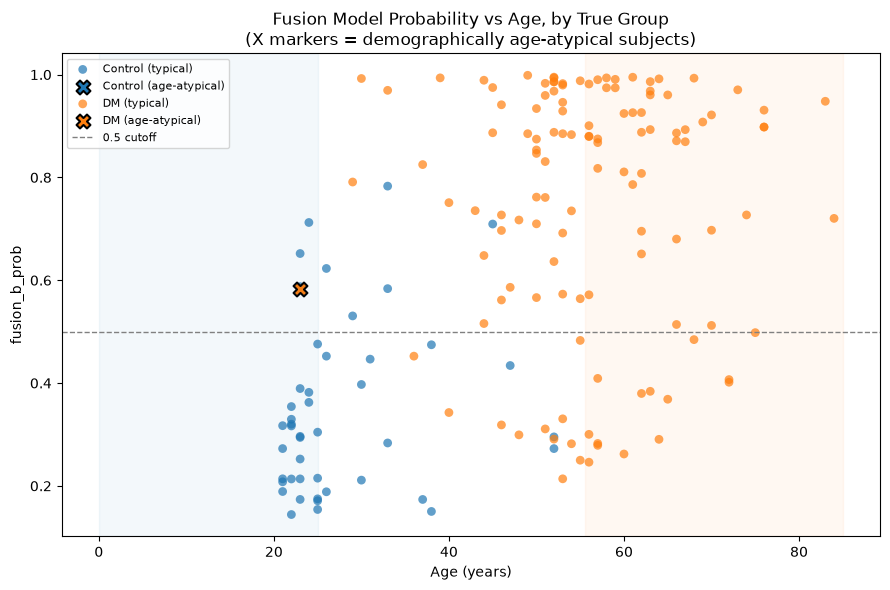

In [7]:
print("=" * 70)
print("SECTION 6: PLOT")
print("=" * 70)

fig, ax = plt.subplots(figsize=(9, 6))

group_colors = {"Control": "#1f77b4", "DM": "#ff7f0e"}

for group_name, color in group_colors.items():
    typical_sub = merged_df.loc[
        (merged_df["Group"] == group_name) & (~merged_df["age_atypical"])
    ]
    atypical_sub = merged_df.loc[
        (merged_df["Group"] == group_name) & (merged_df["age_atypical"])
    ]

    ax.scatter(
        typical_sub["Age_years"], typical_sub["fusion_b_prob"],
        c=color, label=f"{group_name} (typical)", alpha=0.7, s=40, edgecolors="none",
    )
    ax.scatter(
        atypical_sub["Age_years"], atypical_sub["fusion_b_prob"],
        facecolors=color, edgecolors="black", linewidths=1.5,
        marker="X", s=100, label=f"{group_name} (age-atypical)",
    )

ax.axvspan(0, control_median_age, color="#1f77b4", alpha=0.05)
ax.axvspan(dm_median_age, merged_df["Age_years"].max() + 1, color="#ff7f0e", alpha=0.05)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="0.5 cutoff")

ax.set_xlabel("Age (years)")
ax.set_ylabel("fusion_b_prob")
ax.set_title("Fusion Model Probability vs Age, by True Group\n(X markers = demographically age-atypical subjects)")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()


## 7. Qualitative Summary

The cell below renders a summary as Markdown, generated dynamically from the actual numbers
computed in Sections 2–5 above (run Sections 1–5 first).


In [8]:
from IPython.display import Markdown, display

def _fmt_p(p):
    return "<0.0001" if p < 0.0001 else f"{p:.4f}"

def _df_to_md_table(df):
    # Manual Markdown table builder (avoids the optional 'tabulate'
    # dependency that df.to_markdown() requires -- no new dependencies).
    cols = list(df.columns)
    header = "| " + " | ".join(cols) + " |"
    sep = "| " + " | ".join(["---"] * len(cols)) + " |"
    rows = []
    for _, row in df.iterrows():
        cells_fmt = []
        for c in cols:
            v = row[c]
            if isinstance(v, float):
                cells_fmt.append(f"{v:.4g}")
            else:
                cells_fmt.append(str(v))
        rows.append("| " + " | ".join(cells_fmt) + " |")
    return "\n".join([header, sep] + rows)

within_class_flags = within_class_df.loc[
    (within_class_df["p_value"] < 0.05) & (within_class_df["spearman_rho"].abs() >= 0.3)
]

demo_vs_fusion_gap = FUSION_AUC - demographics_only_auc

issues = []
if len(within_class_flags) > 0:
    issues.append(
        f"{len(within_class_flags)} within-class demographic correlation(s) were both "
        f"statistically significant (p<0.05) and moderate-or-larger in size (|rho|>=0.3): "
        f"{', '.join(within_class_flags['comparison'].tolist())}."
    )
if age_gap > 0.15:
    issues.append(f"Age-atypical accuracy is notably lower than age-typical accuracy (gap={age_gap:.3f}).")
if bmi_gap > 0.15:
    issues.append(f"BMI-atypical accuracy is notably lower than BMI-typical accuracy (gap={bmi_gap:.3f}).")

verdict = (
    "no strong evidence of demographic reliance was found"
    if not issues else
    "some evidence of possible demographic reliance was found — see issues below"
)

summary_md = f"""
### Summary of Findings

**Within-class correlation (Section 2).** Spearman correlations between `fusion_b_prob` and
Age/BMI, computed separately within each true class, were:

{_df_to_md_table(within_class_df)}

None of these should be strongly significant with a large effect size if the model is tracking
pathology rather than demographics. {"No such correlations were flagged." if len(within_class_flags) == 0 else "The following were flagged as concerning: " + ", ".join(within_class_flags['comparison'].tolist()) + "."}

**Demographics-only baseline (Section 4).** A logistic regression on Age/Gender/BMI alone reached
AUC = {demographics_only_auc:.3f} (n={n_pooled_demo}), compared to TCI-only AUC = {TCI_ONLY_AUC:.3f}
and fusion AUC = {FUSION_AUC:.3f}. A nontrivial demographics-only AUC is expected here and is not
by itself disqualifying, given the demographic confound documented in Phase 3's raw-data EDA — the
question is whether fusion's advantage over this baseline ({demo_vs_fusion_gap:.3f} AUC points) and
its behavior on atypical subjects (below) indicate it is doing more than encoding demographics.

**Atypical-subject stress test (Section 5).** On subjects whose age profile looks like the wrong
group, fusion accuracy was {age_atypical_acc:.3f} (n={n_age_atypical}) vs {age_typical_acc:.3f}
(n={n_age_typical}) on typical subjects — a gap of {age_gap:.3f}. On subjects whose BMI profile
looks like the wrong group (complete-case only), fusion accuracy was {bmi_atypical_acc:.3f}
(n={n_bmi_atypical}) vs {bmi_typical_acc:.3f} (n={n_bmi_typical}) on typical subjects — a gap of
{bmi_gap:.3f}.

**Verdict:** based on the above, {verdict}.
"""

display(Markdown(summary_md))



### Summary of Findings

**Within-class correlation (Section 2).** Spearman correlations between `fusion_b_prob` and
Age/BMI, computed separately within each true class, were:

| comparison | n | spearman_rho | p_value |
| --- | --- | --- | --- |
| Control-Age | 45 | 0.2162 | 0.1537 |
| DM-Age | 122 | 0.01311 | 0.8861 |
| Control-BMI | 45 | 0.1552 | 0.3086 |
| DM-BMI | 95 | -0.1479 | 0.1526 |

None of these should be strongly significant with a large effect size if the model is tracking
pathology rather than demographics. No such correlations were flagged.

**Demographics-only baseline (Section 4).** A logistic regression on Age/Gender/BMI alone reached
AUC = 0.978 (n=140), compared to TCI-only AUC = 0.859
and fusion AUC = 0.889. A nontrivial demographics-only AUC is expected here and is not
by itself disqualifying, given the demographic confound documented in Phase 3's raw-data EDA — the
question is whether fusion's advantage over this baseline (-0.089 AUC points) and
its behavior on atypical subjects (below) indicate it is doing more than encoding demographics.

**Atypical-subject stress test (Section 5).** On subjects whose age profile looks like the wrong
group, fusion accuracy was 1.000 (n=1) vs 0.801
(n=166) on typical subjects — a gap of -0.199. On subjects whose BMI profile
looks like the wrong group (complete-case only), fusion accuracy was 0.700
(n=20) vs 0.800 (n=120) on typical subjects — a gap of
0.100.

**Verdict:** based on the above, no strong evidence of demographic reliance was found.


## 8. Save Results


In [9]:
print("=" * 70)
print("SECTION 8: SAVE RESULTS")
print("=" * 70)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_out = {
    "within_class_correlations": within_class_df.to_dict(orient="records"),
    "gender_subgroup_auc": gender_df.to_dict(orient="records"),
    "demographics_only_baseline": {
        "auc": demographics_only_auc,
        "n_pooled": n_pooled_demo,
        "n_skipped_null_bmi_test": skipped_null_bmi_test,
        "tci_only_auc_reference": TCI_ONLY_AUC,
        "fusion_auc_reference": FUSION_AUC,
    },
    "atypical_subject_stress_test": {
        "age_version": {
            "control_median_age": control_median_age,
            "dm_median_age": dm_median_age,
            "n_atypical": n_age_atypical,
            "n_typical": n_age_typical,
            "accuracy_atypical": age_atypical_acc,
            "accuracy_typical": age_typical_acc,
            "accuracy_gap": age_gap,
        },
        "bmi_version_complete_case": {
            "control_median_bmi": control_median_bmi,
            "dm_median_bmi": dm_median_bmi,
            "n_atypical": n_bmi_atypical,
            "n_typical": n_bmi_typical,
            "accuracy_atypical": bmi_atypical_acc,
            "accuracy_typical": bmi_typical_acc,
            "accuracy_gap": bmi_gap,
            "note": "complete-case only, n=140",
        },
    },
    "issues_found": issues,
}

out_path = RESULTS_DIR / "confounder_analysis_summary.json"
with open(out_path, "w") as f:
    json.dump(summary_out, f, indent=2, default=float)

print(f"Saved: {out_path}")


SECTION 8: SAVE RESULTS
Saved: results\confounder_analysis_summary.json


## 9. Final Summary


In [10]:
print("=" * 70)
print("SECTION 9: FINAL SUMMARY")
print("=" * 70)

print("\nAUC comparison:")
print(f"  Demographics-only AUC : {demographics_only_auc:.3f}  (n={n_pooled_demo})")
print(f"  TCI-only AUC          : {TCI_ONLY_AUC:.3f}  (reference, Phase 14)")
print(f"  Fusion AUC            : {FUSION_AUC:.3f}  (reference, Phase 16)")

print("\nAtypical-subject accuracy gaps (typical - atypical):")
print(f"  Age version : {age_gap:.3f}  (atypical={age_atypical_acc:.3f}, typical={age_typical_acc:.3f}, n_atypical={n_age_atypical})")
print(f"  BMI version : {bmi_gap:.3f}  (atypical={bmi_atypical_acc:.3f}, typical={bmi_typical_acc:.3f}, n_atypical={n_bmi_atypical})")

print(f"\nOverall verdict: {verdict}")

print(f"\nIssues found: {len(issues)}")
if issues:
    for i, issue in enumerate(issues, start=1):
        print(f"  {i}. {issue}")
else:
    print("  0 issues found.")


SECTION 9: FINAL SUMMARY

AUC comparison:
  Demographics-only AUC : 0.978  (n=140)
  TCI-only AUC          : 0.859  (reference, Phase 14)
  Fusion AUC            : 0.889  (reference, Phase 16)

Atypical-subject accuracy gaps (typical - atypical):
  Age version : -0.199  (atypical=1.000, typical=0.801, n_atypical=1)
  BMI version : 0.100  (atypical=0.700, typical=0.800, n_atypical=20)

Overall verdict: no strong evidence of demographic reliance was found

Issues found: 0
  0 issues found.
